# Lesson 13 — Explainable Machine Learning for Disease Surveillance

## Project Overview

This project demonstrates an end-to-end machine learning workflow using a synthetic public health surveillance dataset containing 2,000 observations.

The objective is to compare classification algorithms, explore sensitivity–precision trade-offs, and explain model predictions using interpretable statistical and machine learning techniques.

## Methodology

- **Dataset:** 2,000 synthetic observations with six predictors and one binary outcome.
- **Algorithms compared:** Logistic Regression, Random Forest, and Gradient Boosting.
- **Model comparison:** Five-fold stratified cross-validation.
- **Threshold selection:** Cross-validated training predictions.
- **Model evaluation:** Held-out test set.
- **Explainability:** Logistic Regression coefficients, odds ratios, permutation importance, and SHAP.

## Key Findings

Logistic Regression achieved the highest cross-validated PR-AUC (0.5325) among the three candidate models.

Using a provisional classification threshold of 0.20, the model achieved the following held-out test performance:

| Metric | Result |
|---|---:|
| Sensitivity | 74.73% |
| Precision | 32.85% |
| F1-score | 0.4564 |
| True positives | 68 |
| False negatives | 23 |
| False positives | 139 |
| True negatives | 170 |

Fever and animal exposure were among the most influential predictors in the model's global and individual explanations.

## Limitations

This project uses entirely synthetic data generated from predefined statistical relationships. Its findings do not establish real-world epidemiological associations or causation.

The selected threshold reflects a hypothetical screening objective rather than a validated operational requirement. The held-out test set was examined during development, so further independent validation would be necessary.

**This project is intended for machine learning education and portfolio demonstration, not clinical diagnosis or operational disease surveillance.**

In [1]:
# Lesson 13: Model Interpretability and Explainable AI

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Lesson 13 environment ready!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Lesson 13 environment ready!
NumPy: 2.5.4
Pandas: 3.0.6
Scikit-learn: 1.9.1


In [2]:
# Lesson 13 — Step 2: Synthetic surveillance dataset

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 2000

df = pd.DataFrame({
    "Age": rng.integers(18, 81, n),
    "Fever": rng.binomial(1, 0.45, n),
    "Headache": rng.binomial(1, 0.40, n),
    "Animal_Exposure": rng.binomial(1, 0.20, n),
    "Travel_History": rng.binomial(1, 0.25, n),
    "Symptom_Duration": rng.integers(1, 15, n)
})

# Artificial scoring rule for demonstration only
risk_score = (
    -4.0
    + 0.015 * df["Age"]
    + 1.2 * df["Fever"]
    + 0.5 * df["Headache"]
    + 1.5 * df["Animal_Exposure"]
    + 0.6 * df["Travel_History"]
    + 0.08 * df["Symptom_Duration"]
)

probability = 1 / (1 + np.exp(-risk_score))

df["Confirmed"] = rng.binomial(1, probability)

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["Confirmed"].value_counts())
print("\nConfirmation percentage:")
print(df["Confirmed"].value_counts(normalize=True).mul(100).round(2))

display(df.head())

Dataset shape: (2000, 7)

Target distribution:
Confirmed
0    1544
1     456
Name: count, dtype: int64

Confirmation percentage:
Confirmed
0    77.2
1    22.8
Name: proportion, dtype: float64


,Age,Fever,Headache,Animal_Exposure,Travel_History,Symptom_Duration,Confirmed
0,23,0,1,0,0,11,0
1,66,0,0,0,1,13,0
2,59,0,0,0,0,3,0
3,45,0,1,0,0,4,0
4,45,1,0,0,1,1,0


In [3]:
# Lesson 13 — Step 3: Train Logistic Regression

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Separate predictors and target
X = df.drop(columns="Confirmed")
y = df["Confirmed"]

# Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Create pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train using training data only
pipeline.fit(X_train, y_train)

# Predictions
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

# Evaluate
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Training observations: 1600
Testing observations: 400

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.96      0.88       309
           1       0.66      0.25      0.37        91

    accuracy                           0.80       400
   macro avg       0.74      0.61      0.62       400
weighted avg       0.78      0.80      0.76       400


Confusion Matrix:
[[297  12]
 [ 68  23]]

ROC-AUC: 0.7279


In [4]:
# Lesson 13 — Step 4A: Compare candidate surveillance models

import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "Sensitivity": "recall",
    "Precision": "precision",
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "PR_AUC": "average_precision"
}

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        **{
            metric: scores[f"test_{metric}"].mean()
            for metric in scoring
        }
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="PR_AUC",
    ascending=False
)

print("MODEL COMPARISON — 5-FOLD CROSS-VALIDATION")
print("=" * 65)

display(comparison_df.round(4))

MODEL COMPARISON — 5-FOLD CROSS-VALIDATION


,Model,Sensitivity,Precision,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.2795,0.6466,0.3886,0.7704,0.5325
2,Gradient Boosting,0.3068,0.4522,0.3647,0.7081,0.4511
1,Random Forest,0.3507,0.4676,0.4000,0.7091,0.4452


In [5]:
# Lesson 13 — Step 4B: Threshold comparison

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# Cross-validated probabilities from training data
cv_prob = cross_val_predict(
    models["Logistic Regression"],
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    predictions = (cv_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Sensitivity": recall_score(y_train, predictions),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(y_train, predictions),
        "Predicted_Positive": predictions.sum(),
        "False_Negatives": ((y_train == 1) & (predictions == 0)).sum(),
        "False_Positives": ((y_train == 0) & (predictions == 1)).sum()
    })

threshold_df = pd.DataFrame(threshold_results)

print("LOGISTIC REGRESSION — THRESHOLD COMPARISON")
print("=" * 65)
print(threshold_df.round(4).to_string(index=False))

LOGISTIC REGRESSION — THRESHOLD COMPARISON
 Threshold  Sensitivity  Precision     F1  Predicted_Positive  False_Negatives  False_Positives
      0.20       0.7397     0.3879 0.5090                 696               95              426
      0.25       0.6411     0.4255 0.5115                 550              131              316
      0.30       0.5452     0.4660 0.5025                 427              166              228
      0.40       0.3644     0.5363 0.4339                 248              232              115
      0.50       0.2795     0.6335 0.3878                 161              263               59


In [6]:
# Lesson 13 — Step 4C: Final held-out test evaluation

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Threshold selected using training data
selected_threshold = 0.20

# Use probabilities from the trained Logistic Regression
test_prob = pipeline.predict_proba(X_test)[:, 1]

# Apply selected threshold
test_pred = (test_prob >= selected_threshold).astype(int)

print("HELD-OUT TEST EVALUATION")
print("=" * 55)
print("Selected threshold:", selected_threshold)

print("\nClassification Report:")
print(classification_report(y_test, test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()

print("\nSurveillance Screening Summary")
print("True positives:", tp)
print("False negatives:", fn)
print("False positives:", fp)
print("True negatives:", tn)

print("\nSensitivity:", round(recall_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred), 4))
print("F1-score:", round(f1_score(y_test, test_pred), 4))

HELD-OUT TEST EVALUATION
Selected threshold: 0.2

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.55      0.68       309
           1       0.33      0.75      0.46        91

    accuracy                           0.59       400
   macro avg       0.60      0.65      0.57       400
weighted avg       0.76      0.59      0.63       400


Confusion Matrix:
[[170 139]
 [ 23  68]]

Surveillance Screening Summary
True positives: 68
False negatives: 23
False positives: 139
True negatives: 170

Sensitivity: 0.7473
Precision: 0.3285
F1-score: 0.4564


In [7]:
# Lesson 13 — Step 5: Coefficients and odds ratios

import numpy as np
import pandas as pd

# Extract trained model and scaler
lr_model = pipeline.named_steps["model"]
scaler = pipeline.named_steps["scaler"]

# Standardized coefficients
coefficients = lr_model.coef_[0]

# Odds ratios for a one-standard-deviation increase
odds_ratios = np.exp(coefficients)

# Build interpretation table
interpretation_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients,
    "Odds_Ratio": odds_ratios,
    "Standard_Deviation": scaler.scale_
})

interpretation_df = interpretation_df.sort_values(
    "Coefficient",
    ascending=False
)

print("MODEL INTERPRETATION — LOGISTIC REGRESSION")
print("=" * 60)

print(interpretation_df.round(4).to_string(index=False))

MODEL INTERPRETATION — LOGISTIC REGRESSION
         Feature  Coefficient  Odds_Ratio  Standard_Deviation
           Fever       0.6828      1.9794              0.4962
 Animal_Exposure       0.6467      1.9092              0.3837
             Age       0.3042      1.3555             18.2277
Symptom_Duration       0.2859      1.3310              4.0675
  Travel_History       0.2571      1.2932              0.4337
        Headache       0.2478      1.2812              0.4858


In [8]:
# Lesson 13 — Step 6: Odds ratios in meaningful units

import numpy as np
import pandas as pd

# Retrieve model components
model = pipeline.named_steps["model"]
scaler = pipeline.named_steps["scaler"]

# Convert standardized coefficients to original units
original_coefficients = model.coef_[0] / scaler.scale_

# Define meaningful changes
changes = {
    "Age": 10,
    "Fever": 1,
    "Headache": 1,
    "Animal_Exposure": 1,
    "Travel_History": 1,
    "Symptom_Duration": 1
}

results = []

for feature, coefficient in zip(
    X_train.columns,
    original_coefficients
):
    change = changes[feature]

    odds_ratio = np.exp(coefficient * change)

    results.append({
        "Feature": feature,
        "Change": (
            "10 years" if feature == "Age"
            else "1 day" if feature == "Symptom_Duration"
            else "No to Yes"
        ),
        "Odds_Ratio": odds_ratio,
        "Odds_Change_Percent": (odds_ratio - 1) * 100
    })

or_table = pd.DataFrame(results)

or_table = or_table.sort_values(
    "Odds_Ratio",
    ascending=False
)

print("INTERPRETABLE ODDS RATIOS")
print("=" * 65)

print(or_table.round(3).to_string(index=False))

INTERPRETABLE ODDS RATIOS
         Feature    Change  Odds_Ratio  Odds_Change_Percent
 Animal_Exposure No to Yes       5.396              439.551
           Fever No to Yes       3.960              295.952
  Travel_History No to Yes       1.809               80.906
        Headache No to Yes       1.665               66.536
             Age  10 years       1.182               18.162
Symptom_Duration     1 day       1.073                7.282


In [9]:
# Lesson 13 — Step 7: Permutation Feature Importance

from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate permutation importance
perm_result = permutation_importance(
    pipeline,
    X_train,
    y_train,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

# Create results table
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_SD": perm_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
)

print("PERMUTATION FEATURE IMPORTANCE — ROC-AUC")
print("=" * 65)

print(importance_df.round(4).to_string(index=False))

PERMUTATION FEATURE IMPORTANCE — ROC-AUC
         Feature  Importance_Mean  Importance_SD
           Fever           0.1027         0.0085
 Animal_Exposure           0.0949         0.0099
             Age           0.0205         0.0038
Symptom_Duration           0.0152         0.0037
  Travel_History           0.0137         0.0031
        Headache           0.0128         0.0041


In [10]:
# Lesson 13 — Step 8A: Prepare SHAP explanations

import shap
import numpy as np
import pandas as pd

# Select a small sample from training data
X_explain = X_train.sample(
    n=100,
    random_state=42
)

# Transform using the fitted scaler
X_explain_scaled = pipeline.named_steps[
    "scaler"
].transform(X_explain)

# Extract trained Logistic Regression
lr_model = pipeline.named_steps["model"]

# Create SHAP explainer
explainer = shap.LinearExplainer(
    lr_model,
    X_explain_scaled
)

# Calculate SHAP values
shap_values = explainer(X_explain_scaled)

print("SHAP EXPLAINER READY")
print("=" * 50)

print("Observations explained:", len(X_explain))
print("Features:", X_explain.shape[1])
print("SHAP values shape:", shap_values.values.shape)

print("\nFeature names:")
print(X_explain.columns.tolist())

SHAP EXPLAINER READY
Observations explained: 100
Features: 6
SHAP values shape: (100, 6)

Feature names:
['Age', 'Fever', 'Headache', 'Animal_Exposure', 'Travel_History', 'Symptom_Duration']


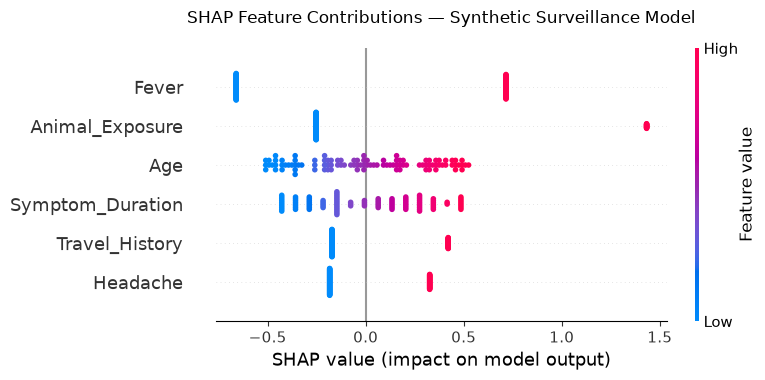

In [11]:
# Lesson 13 — Step 8B: SHAP Summary Visualization

import shap
import matplotlib.pyplot as plt

# Attach original feature values and names
shap_explanation = shap.Explanation(
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=X_explain.values,
    feature_names=X_explain.columns.tolist()
)

# Create beeswarm plot
shap.plots.beeswarm(
    shap_explanation,
    max_display=6,
    show=False
)

plt.title(
    "SHAP Feature Contributions — Synthetic Surveillance Model",
    fontsize=12,
    pad=18
)

plt.tight_layout()
plt.show()

INDIVIDUAL SIMULATED CASE EXPLANATION

Observation characteristics:
 Age  Fever  Headache  Animal_Exposure  Travel_History  Symptom_Duration
  49      1         1                1               1                 9

Predicted probability: 0.8229
Screening threshold: 0.2
Model classification: Potential positive


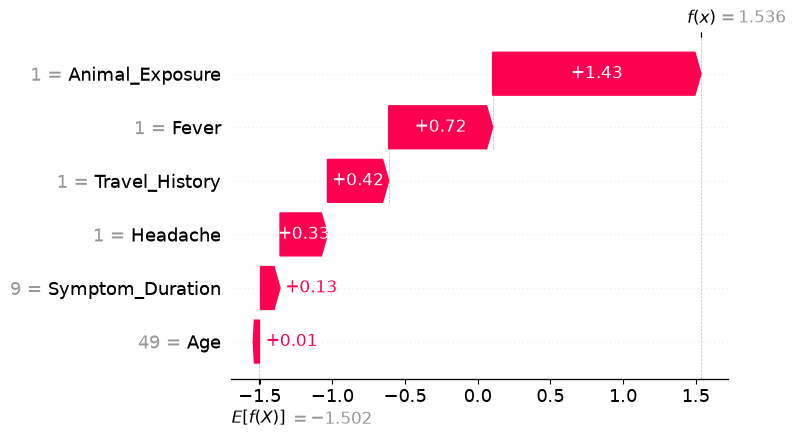

In [12]:
# Lesson 13 — Step 8C: Individual SHAP explanation

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select a simulated observation predicted positive
# using our provisional surveillance threshold
sample_probabilities = pipeline.predict_proba(X_explain)[:, 1]

positive_indices = np.where(
    sample_probabilities >= selected_threshold
)[0]

# Choose the highest-scoring observation
patient_idx = int(np.argmax(sample_probabilities))

# Display observation characteristics
patient = X_explain.iloc[[patient_idx]]

print("INDIVIDUAL SIMULATED CASE EXPLANATION")
print("=" * 60)

print("\nObservation characteristics:")
print(patient.to_string(index=False))

print("\nPredicted probability:",
      round(sample_probabilities[patient_idx], 4))

print("Screening threshold:", selected_threshold)

print(
    "Model classification:",
    "Potential positive"
    if sample_probabilities[patient_idx] >= selected_threshold
    else "Negative"
)

# SHAP waterfall plot for this observation
shap.plots.waterfall(
    shap_explanation[patient_idx],
    max_display=6,
    show=False
)

plt.tight_layout()
plt.show()

In [13]:
# Lesson 13 — Step 9: Validate SHAP explanation

from scipy.special import expit
import numpy as np

# Baseline plus individual SHAP contributions
base_value = float(
    np.asarray(shap_explanation.base_values[patient_idx]).item()
)

feature_contributions = shap_explanation.values[patient_idx]

reconstructed_log_odds = (
    base_value + feature_contributions.sum()
)

# Convert log-odds to probability
reconstructed_probability = expit(reconstructed_log_odds)

# Original model probability
model_probability = pipeline.predict_proba(
    X_explain.iloc[[patient_idx]]
)[0, 1]

print("SHAP EXPLANATION VALIDATION")
print("=" * 55)

print("Baseline log-odds:", round(base_value, 4))
print("Sum of SHAP contributions:",
      round(feature_contributions.sum(), 4))
print("Reconstructed log-odds:",
      round(reconstructed_log_odds, 4))

print("\nProbability from SHAP:",
      round(reconstructed_probability, 4))
print("Probability from model:",
      round(model_probability, 4))

print("\nExplanation matches model:",
      np.isclose(
          reconstructed_probability,
          model_probability
      ))

SHAP EXPLANATION VALIDATION
Baseline log-odds: -1.5015
Sum of SHAP contributions: 3.0374
Reconstructed log-odds: 1.5359

Probability from SHAP: 0.8229
Probability from model: 0.8229

Explanation matches model: True


In [14]:
# Lesson 13 — Step 10: Final technical checks

import numpy as np

checks = {
    "Dataset contains 2000 observations": len(df) == 2000,
    "Six predictors available": X_train.shape[1] == 6,
    "Three candidate models compared": len(comparison_df) == 3,
    "Threshold comparison completed": len(threshold_df) == 5,
    "Selected threshold is 0.20": selected_threshold == 0.20,
    "Six features interpreted": len(or_table) == 6,
    "Permutation importance completed": len(importance_df) == 6,
    "SHAP explanations available": shap_values.values.shape == (100, 6),
    "SHAP reconstruction matches prediction": np.isclose(
        reconstructed_probability,
        model_probability
    )
}

print("LESSON 13 — FINAL TECHNICAL AUDIT")
print("=" * 60)

for check, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {check}")

print("\nOverall status:",
      "ALL CHECKS PASSED" if all(checks.values())
      else "REVIEW REQUIRED")

LESSON 13 — FINAL TECHNICAL AUDIT
PASS | Dataset contains 2000 observations
PASS | Six predictors available
PASS | Three candidate models compared
PASS | Threshold comparison completed
PASS | Selected threshold is 0.20
PASS | Six features interpreted
PASS | Permutation importance completed
PASS | SHAP explanations available
PASS | SHAP reconstruction matches prediction

Overall status: ALL CHECKS PASSED
